![Banner](../../../../Images/Banner/07_remote_sensing/09_12_surface_energy_balance_modeling.png)

# From Snapshots to Seasonal ET and Crop Water Use

A Landsat energy balance gives ET for the moment of an image and, through the reference ET fraction,
for that day. Water managers need months and seasons: how much water an orchard used from April to
October, how much a district consumed in a drought year. Between clear images the fraction must be
interpolated, and the daily weather carries it to every day. This notebook runs METRIC on every
clear Landsat image of 2024 over the Westside San Joaquin Valley, estimates the hot anchor's
evaporation after winter rain with a soil water balance, interpolates ETrF to every day, accumulates
monthly and annual ET, and turns the result into crop water use and satellite crop coefficients.
It ends by measuring how much the annual total depends on the number of clear images.

## Overview

### Interpolate the fraction, not ET

ET on any day is the product of the crop's state (how much leaf area, how wet the soil) and the
weather of the day. The crop's state changes slowly over weeks; the weather changes daily. METRIC
therefore interpolates ETrF between images and multiplies by each day's alfalfa reference ET:

`ET_day = ETrF_interpolated(day) x ETr(day)`, `ET_season = sum over days`

Interpolating ET itself would carry a hot image day's ET into a cool cloudy week. Linear
interpolation is the usual choice; splines can overshoot after a harvest. Long gaps (winter clouds)
make the interpolated fraction unreliable, so the interpolation stops beyond a maximum gap.

### The hot anchor after rain

In winter, rain wets bare soil and it evaporates for days. METRIC estimates the hot anchor's
`ETrF_hot` with the FAO-56 two-stage soil evaporation model, a daily water balance of the top
10 to 15 cm of soil:

- Rain refills the evaporating layer (depletion `De` falls).
- While `De` is below the readily evaporable water `REW` (stage 1), the surface evaporates at the
  energy-limited rate, `Ke = Ke_max`.
- Beyond `REW` (stage 2), evaporation falls linearly to zero at the total evaporable water `TEW`:
  `Kr = (TEW - De) / (TEW - REW)`, `Ke = Kr Ke_max`.

`ETrF_hot` is the `Ke` of the image date. In the dry summer it is zero.

### Crop coefficients from space

ETrF is a crop coefficient on the alfalfa basis. Multiplying by `ETr/ETo` puts it on the grass
basis used by FAO-56 (`Kc = ETrF ETr / ETo`), so satellite estimates can be compared with the
tabulated values that irrigation districts still use for planning. The satellite values include
the actual water management (deficit irrigation, weeds, cover crops, harvest dates), which the
tables cannot.

## Seasonal ET with GeoLattice

| Function | Purpose |
|---|---|
| `sd.run_metric_scene(ds, etrf_hot=...)` | METRIC for each cached scene |
| `seb.interpolate_etrf(stack, max_gap_days=, extrapolate=)` | daily ETrF between clear images |
| `seb.seasonal_et(etrf_daily, etr_daily, freq=)` | seasonal or monthly ET totals |
| `seb.zonal_et(et, zones, names=, pixel_area=)` | ET and water volume per crop or field |
| `sd.daily_reference` | daily ERA5 alfalfa and grass reference ET (notebook 02) |

### Learning objectives

1. Explain why ETrF, not ET, is interpolated between images, and what limits the interpolation.
2. Estimate the hot anchor's ETrF after rain with the FAO-56 soil evaporation model.
3. Build a daily ETrF cube from 27 images and accumulate monthly and annual ET.
4. Compute ET and water volumes per crop, and satellite crop coefficients through the season.
5. Replace METRIC where it is not reliable (winter) and check the result with a water balance.
6. Measure how the number of clear images changes the seasonal total.

### Data

| Dataset | Content |
|---|---|
| Landsat 8 and 9 C2 L2, 27 scenes of 2024 | path 42 row 35, cached by `sd.load_scene` (notebook 01) |
| ERA5 daily (Open-Meteo) | rain and the daily alfalfa and grass reference ET of 2024 |
| USDA CDL 2024 | crop type of each pixel |

The METRIC runs take a few minutes the first time and are cached in
`outputs/etrf_westside_2024.nc`.

### Contents

- Setup
- The hot anchor's ETrF from a soil water balance
- METRIC on every image
- Daily ETrF
- Rain between images
- Winter: where METRIC is not reliable
- Monthly and annual ET
- Crop water use
- Satellite crop coefficients
- How many images are enough?
- Summary and exercises

## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import rioxarray  # noqa: F401  (registers the .rio accessor)
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.rsense.surface_energy_balance as seb  # energy balance and ET models
import seb_data as sd  # chapter helper: downloads, caches and loads the scenes

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
OUT = Path("outputs")  # results written by this chapter
OUT.mkdir(exist_ok=True)  # create it if needed
print("GeoLattice", geolattice.__version__, "| data folder", sd.DATA.relative_to(sd.DATA.parents[3]))  # versions and paths

SITE = sd.WESTSIDE  # Westside San Joaquin Valley
ref = sd.daily_reference(SITE, "2024-01-01", "2024-12-31")  # daily ETr, ETo and rain from ERA5
rain = ref["precip"]  # mm/day
ds0 = sd.load_scene()  # one stack for the grid and the crop map
cdl = ds0.cdl  # CDL 2024 on the Landsat grid
pixel_area = 30.0 * 30.0  # m2

GeoLattice 0.3.49 | data folder GeoLattice/Data/08_remote_sensing/08_12_surface_energy_balance


## The hot anchor's ETrF from a soil water balance

The evaporating layer is given a total evaporable water of 25 mm and a readily evaporable water of
9 mm, typical of the clay loams of the Westside (FAO-56 Table 19), and `Ke_max = 1.0` on the alfalfa
basis. The balance runs daily through 2024 with ERA5 rain and ETr.

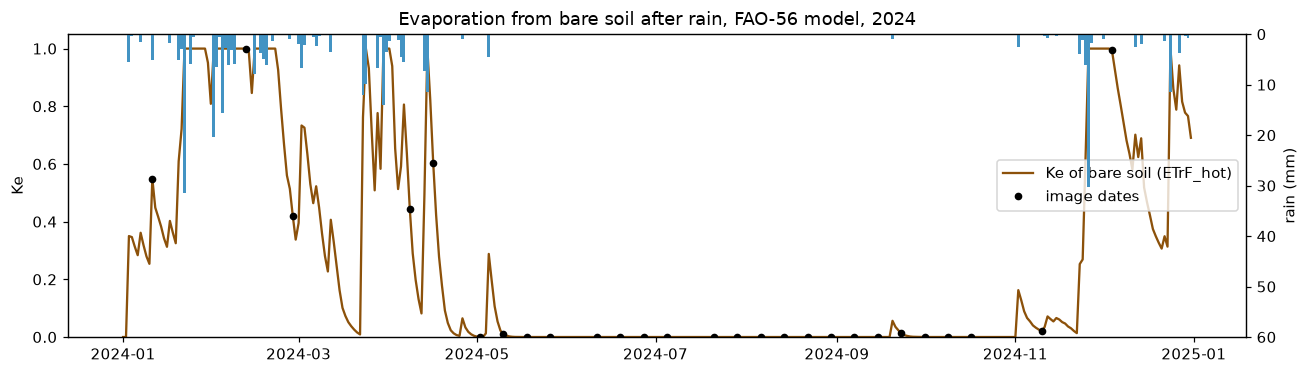

,ETrF_hot
time,
2024-01-11,0.55
2024-02-12,1.00
2024-02-28,0.42
2024-04-08,0.44
2024-04-16,0.60
2024-05-10,0.01
2024-09-23,0.01
2024-11-10,0.02
2024-12-04,0.99


In [2]:
def soil_evaporation_ke(rain, etr, tew=25.0, rew=9.0, ke_max=1.0):  # FAO-56 two-stage evaporation of bare soil
    de, out = tew, []  # start dry (fully depleted)
    for p_, e_ in zip(rain.values, etr.values):  # day by day
        de = max(de - p_, 0.0)  # rain refills the layer
        kr = 1.0 if de <= rew else max((tew - de) / (tew - rew), 0.0)  # stage 1 or stage 2
        ke = kr * ke_max  # evaporation coefficient
        de = min(de + ke * e_, tew)  # evaporation depletes the layer
        out.append(ke)  # Ke of the day
    return pd.Series(out, index=rain.index)  # daily Ke


ke = soil_evaporation_ke(rain, ref["etr"])  # daily Ke of a bare field
fig, ax = plt.subplots(figsize=(12, 3.5))  # one panel
ax.plot(ke, color="#8c510a", label="Ke of bare soil (ETrF_hot)"); ax.set_ylabel("Ke"); ax.set_ylim(0, 1.05)  # Ke
ax2 = ax.twinx(); ax2.bar(rain.index, rain, color="#4393c3", width=1); ax2.set_ylim(60, 0); ax2.set_ylabel("rain (mm)")  # rain from the top
dates = [pd.Timestamp(s[17:25]) for s in sd.SEASON_2024]  # image dates
ax.plot(dates, ke.reindex(dates), "ko", ms=4, label="image dates"); ax.legend(loc="center right")  # Ke at the images
ax.set_title("Evaporation from bare soil after rain, FAO-56 model, 2024"); plt.tight_layout(); plt.show()  # draw
etrf_hot = ke.reindex(dates).round(2)  # ETrF_hot for each image
etrf_hot[etrf_hot > 0].to_frame("ETrF_hot")  # images where the hot anchor still evaporates

After each winter storm the bare soil evaporates at the full rate for a few days and then dries;
from May on the hot anchor's ETrF is zero on every image date. Only the images listed in the table
use a non-zero `etrf_hot`.

## METRIC on every image

Each scene goes through the same chain as notebook 06: inputs, automated anchors, overpass and daily
reference ET from ERA5, and METRIC with the hot anchor's ETrF from the balance above. Cloudy pixels
are left empty.

In [3]:
cube_path = OUT / "etrf_westside_2024.nc"  # cached result
if cube_path.exists():  # reuse earlier runs
    cube = xr.open_dataset(cube_path).load()  # ETrF and vegetation cover, (time, y, x)
    log = pd.read_csv(OUT / "etrf_westside_2024_log.csv", index_col=0)  # calibration log
else:  # run METRIC on every scene (a few minutes)
    layers, covers, rows = [], [], []  # results
    for sid in sd.SEASON_2024:  # every 2024 scene
        s = sd.load_scene(sid)  # cached stack
        q = sd.energy_inputs(s)  # inputs and anchors
        d = pd.Timestamp(s.attrs["datetime"]).normalize()  # image date
        r = sd.run_metric_scene(s, q, etrf_hot=float(etrf_hot.get(d, 0.0)))  # METRIC
        layers.append(r.etrf.where(q["mask"]).expand_dims(time=[d]).astype("float32"))  # ETrF, clouds masked
        covers.append(seb.fractional_cover(q["ndvi"]).where(q["mask"]).expand_dims(time=[d]).astype("float32"))  # vegetation cover
        rows.append({"date": d.date(), "clear %": round(100 * float(q["mask"].mean()), 1), "ETrF_hot": float(etrf_hot.get(d, 0.0)),
                     "cold LST (C)": round(q["anchors"]["cold"]["lst"] - 273.15, 1), "hot LST (C)": round(q["anchors"]["hot"]["lst"] - 273.15, 1),
                     "ETr24 (mm)": round(q["etr_daily"], 2), "ETrF median": round(float(r.etrf.median()), 3)})  # calibration log
    cube = xr.Dataset({"etrf": xr.concat(layers, "time"), "fc": xr.concat(covers, "time")})  # (time, y, x)
    log = pd.DataFrame(rows).set_index("date")  # table
    cube.to_netcdf(cube_path, encoding={v: {"zlib": True, "complevel": 4} for v in cube.data_vars})  # cache
    log.to_csv(OUT / "etrf_westside_2024_log.csv")  # cache
etrf, fc = cube.etrf, cube.fc  # the two cubes
print(dict(etrf.sizes))  # 27 images
log  # one row per image

{'time': 27, 'y': 953, 'x': 926}


,clear %,ETrF_hot,cold LST (C),hot LST (C),ETr24 (mm),ETrF median
date,,,,,,
2024-01-11,99.9,0.55,9.2,14.1,2.93,0.857
2024-02-12,100.0,1.00,14.0,22.4,2.10,1.112
2024-02-28,100.0,0.42,17.2,29.3,3.14,0.633
2024-04-08,100.0,0.44,16.4,26.4,5.56,0.603
2024-04-16,77.0,0.60,22.2,35.8,4.81,0.848
2024-05-02,100.0,0.00,25.3,41.3,10.34,0.302
2024-05-10,100.0,0.01,29.3,52.1,8.51,0.408
2024-05-18,100.0,0.00,30.3,53.7,8.66,0.392
2024-05-26,100.0,0.00,28.0,51.0,8.67,0.229


## Daily ETrF

`seb.interpolate_etrf` fills each pixel's days between clear images linearly, stops at gaps longer
than 50 days (none exceeds that for most pixels; cloudy pixels of the 10 November image make some
longer), and holds the first and last values to the ends of the year.

{'time': 366, 'y': 953, 'x': 926} | pixel-days without a value: 0.01%


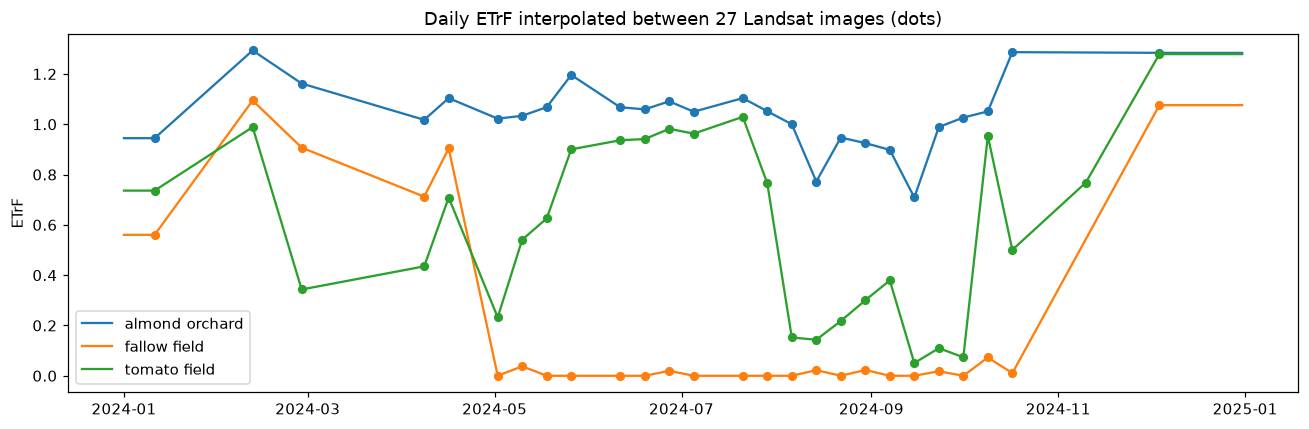

In [4]:
daily = seb.interpolate_etrf(etrf, start="2024-01-01", end="2024-12-31", max_gap_days=50, extrapolate=True)  # (366, y, x)
print(dict(daily.sizes), f"| pixel-days without a value: {float(daily.isnull().mean()):.2%}")  # coverage
pts = {"almond orchard": (193, 25), "fallow field": (206, 193)}  # the cold and hot anchors of 5 July as examples
pts["tomato field"] = tuple(int(v) for v in np.argwhere((cdl == 54).values & (etrf.sel(time="2024-07-05").squeeze() > 0.9).values)[100])  # a well watered tomato pixel
fig, ax = plt.subplots(figsize=(12, 4))  # one panel
for name, (iy, ix) in pts.items():  # three pixels
    line = ax.plot(daily.time, daily[:, iy, ix], lw=1.5, label=name)[0]  # interpolated ETrF
    ax.plot(etrf.time, etrf[:, iy, ix], "o", color=line.get_color(), ms=5)  # image values
ax.set_ylabel("ETrF"); ax.legend(); ax.set_title("Daily ETrF interpolated between 27 Landsat images (dots)"); plt.tight_layout(); plt.show()  # draw

The orchard keeps a high ETrF from spring to autumn. The tomato field rises from planting to full
cover in early summer and drops at harvest. The fallow field stays low except after winter rains,
when its bare soil evaporates. Between images the lines are straight: a harvest that happened a few
days after an image appears later and more gradually than it was.

## Rain between images

Straight lines between images carry the soil wetness of an image day across the following weeks:
an image taken the day after a storm makes every bare field look wet for a month, and a storm
between two dry images is missed. METRIC corrects the uncovered part of each pixel with the daily
soil evaporation of the FAO-56 balance (Allen et al. 2007). The soil evaporation seen on the image
dates is interpolated too, removed, and replaced by the daily value, weighted by the bare fraction
`1 - fc`:

`ETrF_adj(day) = ETrF_interp(day) + (1 - fc_interp(day)) (Ke(day) - Ke_interp(day))`

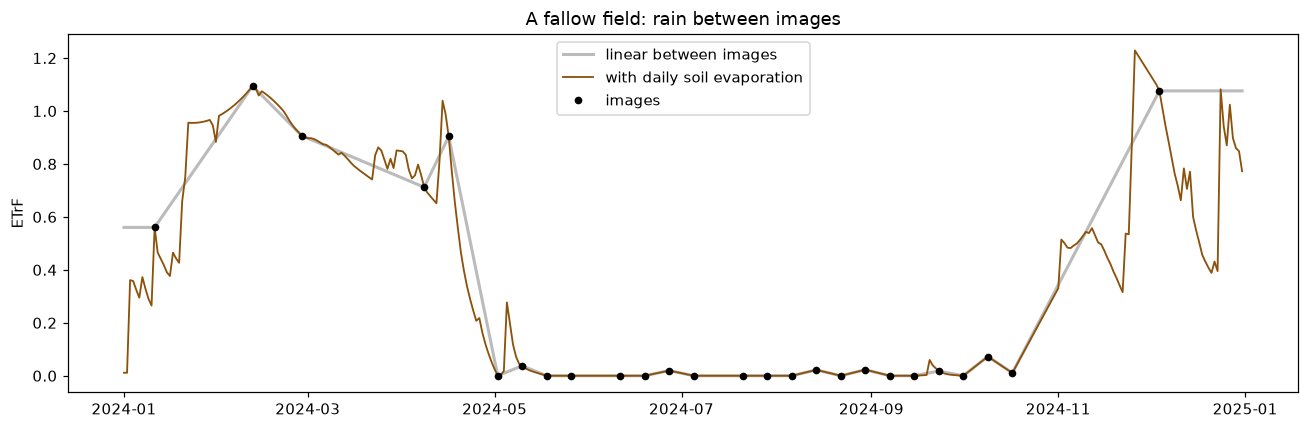

In [5]:
fc_daily = seb.interpolate_etrf(fc, start="2024-01-01", end="2024-12-31", max_gap_days=50, extrapolate=True, clip=(0, 1))  # daily cover
ke_img = ke.reindex(pd.DatetimeIndex(etrf.time.values))  # Ke on the image dates
days = pd.date_range("2024-01-01", "2024-12-31")  # every day of 2024
ke_interp = ke_img.reindex(days.union(ke_img.index)).interpolate("time").ffill().bfill().reindex(days)  # Ke as the images see it
corr = xr.DataArray((ke.reindex(days) - ke_interp).values, coords={"time": days}, dims="time")  # daily minus interpolated soil evaporation
daily_adj = (daily + (1 - fc_daily) * corr).clip(0, 1.3)  # adjusted daily ETrF
fig, ax = plt.subplots(figsize=(12, 4))  # one panel
iy, ix = pts["fallow field"]  # the fallow pixel
ax.plot(daily.time, daily[:, iy, ix], color="#bbbbbb", lw=2, label="linear between images")  # before
ax.plot(daily_adj.time, daily_adj[:, iy, ix], color="#8c510a", lw=1.2, label="with daily soil evaporation")  # after
ax.plot(etrf.time, etrf[:, iy, ix], "ko", ms=4, label="images")  # image values
ax.set_ylabel("ETrF"); ax.legend(); ax.set_title("A fallow field: rain between images"); plt.tight_layout(); plt.show()  # draw

After the adjustment the fallow field's ETrF falls back within days of each storm instead of staying
high until the next image, and storms between images appear as short pulses. Vegetated pixels change
little, because the correction is weighted by their bare fraction. The rest of the notebook uses the
adjusted daily ETrF.

## Winter: where METRIC is not reliable

The calibration log shows the winter images (January, February, November and December) with anchors
only 5 to 8 K apart and a daily alfalfa reference ET of 1 to 3 mm. On those dates METRIC gives nearly
every pixel, fallow land included, a fraction close to or above 1 (the crop coefficient section below
lists them). With so little contrast the calibration is poorly constrained, and wet soil after rain
makes both anchors evaporate. Operational METRIC work in California concentrates on the growing
season for this reason. From November to March this notebook uses a cover-based coefficient
instead, in the spirit of SIMS: green cover transpires at the reference rate, bare soil evaporates
as the FAO-56 balance allows.

`ETrF_off(day) = 0.95 fc(day) + (1 - fc(day)) Ke(day)`, from November to March

## Monthly and annual ET

Each day's fraction times that day's ETr, summed by month and over the year. Three versions of the
annual total show the effect of each step.

window mean annual ET: linear 1198 mm, rain adjusted 1167 mm, winter replaced 1102 mm
April to October (METRIC) 865 mm | alfalfa reference 2366 mm | rain 320 mm (38 mm from April to October)


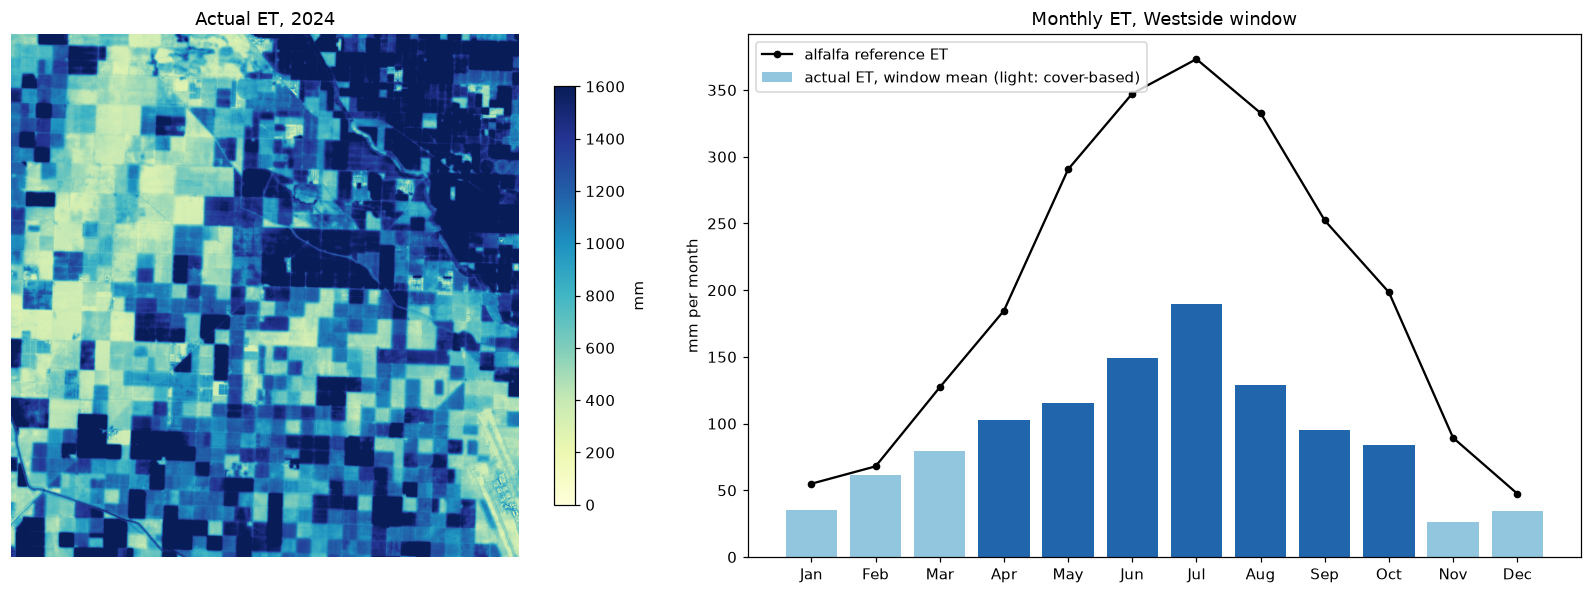

In [6]:
ke_da = xr.DataArray(ke.reindex(days).values, coords={"time": days}, dims="time")  # daily Ke as a DataArray
off = (daily_adj.time.dt.month <= 3) | (daily_adj.time.dt.month >= 11)  # November to March
etrf_off = (0.95 * fc_daily + (1 - fc_daily) * ke_da).clip(0, 1.05)  # cover-based coefficient
final = xr.where(off, etrf_off, daily_adj)  # METRIC April to October, cover-based in winter
etr_series = ref["etr"]  # daily alfalfa reference ET, mm
annual_linear = seb.seasonal_et(daily, etr_series)  # linear ETrF only
annual_rain = seb.seasonal_et(daily_adj, etr_series)  # with the rain adjustment
annual = seb.seasonal_et(final, etr_series)  # with the winter replacement as well
monthly = seb.seasonal_et(final, etr_series, freq="MS")  # mm per month
season = seb.seasonal_et(daily_adj, etr_series, start="2024-04-01", end="2024-10-31")  # METRIC irrigation season
print(f"window mean annual ET: linear {float(annual_linear.mean()):.0f} mm, rain adjusted {float(annual_rain.mean()):.0f} mm, "
      f"winter replaced {float(annual.mean()):.0f} mm")  # effect of each step
print(f"April to October (METRIC) {float(season.mean()):.0f} mm | alfalfa reference {etr_series.sum():.0f} mm | rain {rain.sum():.0f} mm "
      f"({rain.loc['2024-04':'2024-10'].sum():.0f} mm from April to October)")  # totals
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1, 1.2]})  # map and bars
im = ax[0].imshow(annual, cmap="YlGnBu", vmin=0, vmax=1600); plt.colorbar(im, ax=ax[0], shrink=0.8, label="mm")  # annual ET map
ax[0].set_title("Actual ET, 2024"); ax[0].axis("off")  # title
mm = monthly.mean(["y", "x"]).to_series()  # window mean per month
ax[1].bar(mm.index.strftime("%b"), mm.values, color=np.where(mm.index.month.isin([1, 2, 3, 11, 12]), "#92c5de", "#2166ac"),
          label="actual ET, window mean (light: cover-based)")  # monthly ET
ax[1].plot(mm.index.strftime("%b"), etr_series.resample("MS").sum().values, "k-o", ms=4, label="alfalfa reference ET")  # reference
ax[1].set_ylabel("mm per month"); ax[1].legend(); ax[1].set_title("Monthly ET, Westside window")  # labels
plt.tight_layout(); plt.show()  # draw

The rain adjustment lowers the window's annual mean from 1,198 to 1,167 mm and the winter
replacement to 1,102 mm. Most of the ET happens from May to September, when the orchards and summer
crops are at full canopy, and it stays well below the alfalfa reference because much of the window
is fallow or harvested for part of the year.

## Crop water use

`seb.zonal_et` groups the annual ET by CDL class and converts depths to volumes with the pixel area.
One acre-foot is 1,233.5 m3.

In [7]:
use = seb.zonal_et(annual, cdl, names=sd.CDL_NAMES, pixel_area=pixel_area, min_count=5000)  # per crop class
use["annual, linear only (mm)"] = seb.zonal_et(annual_linear, cdl, pixel_area=pixel_area, min_count=5000)["mean_mm"]  # before both adjustments
use["season Apr-Oct (mm)"] = seb.zonal_et(season, cdl, pixel_area=pixel_area, min_count=5000)["mean_mm"]  # irrigation season
use["volume (thousand acre-feet)"] = use.volume_m3 / 1233.5 / 1000  # US units
print(f"total for the window: {annual.sum().item() / 1000 * pixel_area / 1e6:.0f} million m3 "
      f"({annual.sum().item() / 1000 * pixel_area / 1233.5 / 1000:.0f} thousand acre-feet) over {annual.notnull().sum().item() * pixel_area / 1e4:,.0f} ha")  # total volume
fallow_et = float(annual.where(cdl == 61).mean())  # unirrigated fallow land, mm
print(f"water balance check: fallow land ET {fallow_et:.0f} mm against {rain.sum():.0f} mm of rain "
      f"({float(season.where(cdl == 61).mean()):.0f} mm of it from April to October, when {rain.loc['2024-04':'2024-10'].sum():.0f} mm fell)")  # plausibility
use[["name", "area_ha", "annual, linear only (mm)", "mean_mm", "p10_mm", "p90_mm", "season Apr-Oct (mm)", "volume (thousand acre-feet)"]].round(1)  # table

total for the window: 875 million m3 (709 thousand acre-feet) over 79,423 ha
water balance check: fallow land ET 575 mm against 320 mm of rain (357 mm of it from April to October, when 38 mm fell)


,name,area_ha,"annual, linear only (mm)",mean_mm,p10_mm,p90_mm,season Apr-Oct (mm),volume (thousand acre-feet)
zone,,,,,,,,
204,Pistachios,14583.2,1380.7,1291.5,634.9,1771.9,1056.4,152.7
61,Fallow/idle cropland,13113.4,671.9,574.9,379.2,796.2,356.6,61.1
75,Almonds,7310.4,1871.2,1755.9,736.3,2283.2,1477.0,104.1
54,Tomatoes,7142.8,1272.2,1157.1,1010.4,1314.3,962.6,67.0
69,Grapes,4987.0,1679.0,1559.2,1158.3,1871.8,1319.0,63.0
176,Grassland/pasture,4480.6,801.7,740.2,394.8,1178.6,490.1,26.9
24,Winter wheat,4402.1,854.4,779.2,462.9,1143.8,519.1,27.8
2,Cotton,3697.6,1526.5,1407.9,1155.2,1620.9,1195.3,42.2
208,Garlic,1706.5,1120.6,1020.6,825.6,1204.5,782.0,14.1


Pistachios and almonds use the most water in total, because they cover the largest area and keep
their canopy all season. Per hectare, almonds, grapes, cotton and alfalfa use the most over the
April to October season (1,250 to 1,500 mm), pistachios and tomatoes about 1,000 mm. The spread
between the 10th and 90th percentiles within each crop shows how much management varies from field
to field; it is what makes field-scale ET useful for water accounting.

The water balance check is a warning. Fallow land is not irrigated, so over a year its ET cannot
exceed the rain (320 mm) by much; yet it gets 575 mm, and 357 mm of that between April and October,
when only 38 mm of rain fell. METRIC gives typical fallow fields an ETrF of about 0.15 to 0.2 in
summer, because they are a little cooler than the hot anchor, and multiplied by a reference ET of 10
to 15 mm a day that small fraction adds up. The orchard totals are also higher than the 1,100 to
1,400 mm a year often quoted for mature, fully irrigated almonds in the San Joaquin Valley. Two
causes act on every pixel: the ERA5 reference ET is not corrected for aridity (notebook 02 put that
effect at up to 12 %), and the 1.05 cold anchor in an advective heat wave. Notebook 11 turns the
fallow check into a bias estimate and asks which model and reference ET choices bring the totals
down.

## Satellite crop coefficients

The median ETrF of each crop on each image date, converted to the grass basis with that day's
`ETr/ETo`, gives a seasonal crop coefficient curve. The dashed lines are approximate mid-season
values from FAO-56 Table 12 for standard, well watered conditions.

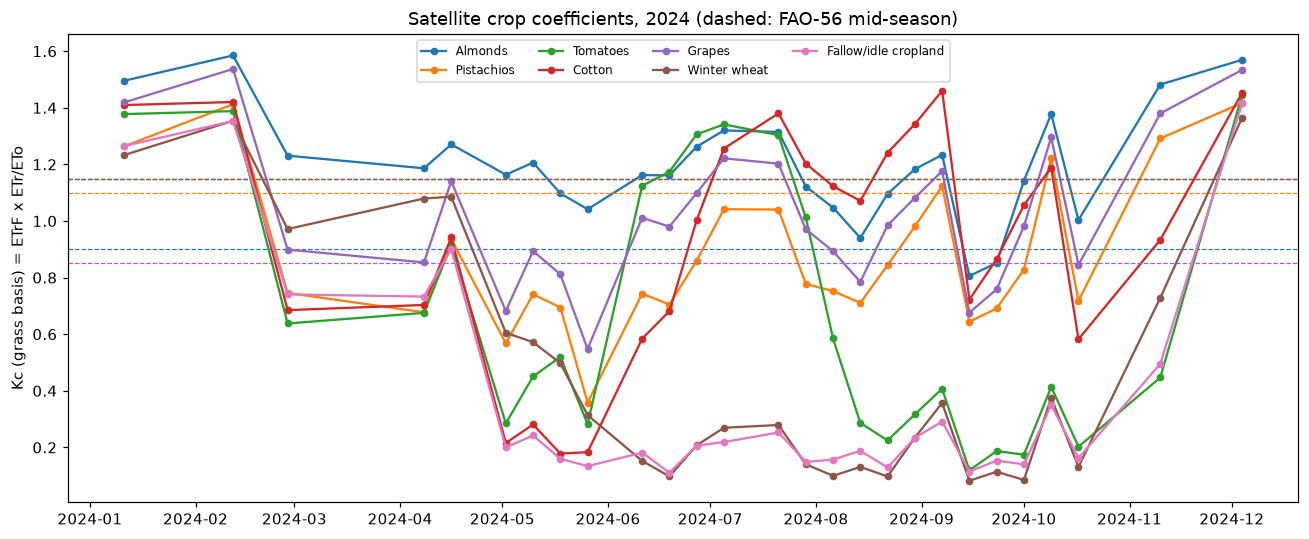

,Almonds,Pistachios,Tomatoes,Cotton,Grapes,Winter wheat,Fallow/idle cropland
2024-01-11,1.50,1.26,1.38,1.41,1.42,1.23,1.26
2024-02-12,1.58,1.41,1.39,1.42,1.54,1.35,1.35
2024-12-04,1.57,1.42,1.44,1.45,1.53,1.36,1.42


,"satellite Kc, mid-season",FAO_56_mid
Almonds,1.16,0.90
Pistachios,0.78,1.10
Tomatoes,1.17,1.15
Cotton,1.12,1.15
Grapes,0.98,0.85
Winter wheat,1.08,1.15
Fallow/idle cropland,0.19,NaN


In [8]:
CROPS = {75: "Almonds", 204: "Pistachios", 54: "Tomatoes", 2: "Cotton", 69: "Grapes", 24: "Winter wheat", 61: "Fallow/idle cropland"}  # crops to follow
FAO_MID = {"Almonds": 0.90, "Pistachios": 1.10, "Tomatoes": 1.15, "Cotton": 1.15, "Grapes": 0.85, "Winter wheat": 1.15}  # approximate FAO-56 Kc mid (grass basis)
ratio = (ref["etr"] / ref["eto"]).reindex(etrf.time.values)  # ETr/ETo on each image date
kc = pd.DataFrame({name: [float(etrf.sel(time=t).where(cdl == code).median()) * ratio.loc[t] for t in etrf.time.values]
                   for code, name in CROPS.items()}, index=pd.DatetimeIndex(etrf.time.values))  # satellite Kc per crop and date
fig, ax = plt.subplots(figsize=(12, 5))  # one panel
for name in CROPS.values():  # every crop
    line = ax.plot(kc.index, kc[name], "o-", ms=4, label=name)[0]  # satellite Kc
    if name in FAO_MID:  # tabulated value
        ax.axhline(FAO_MID[name], color=line.get_color(), ls="--", lw=0.8)  # FAO-56 mid-season
ax.set_ylabel("Kc (grass basis) = ETrF x ETr/ETo"); ax.legend(ncol=4, fontsize=8); ax.set_title("Satellite crop coefficients, 2024 (dashed: FAO-56 mid-season)")  # labels
plt.tight_layout(); plt.show()  # draw
peak = kc.loc["2024-06-15":"2024-08-15"].median()  # mid-season median for the summer crops and orchards
peak["Winter wheat"] = kc.loc["2024-04-01":"2024-04-30", "Winter wheat"].median()  # wheat peaks in April
display(kc.loc[["2024-01-11", "2024-02-12", "2024-12-04"]].round(2))  # winter images: METRIC fractions near or above 1 everywhere
peak.round(2).to_frame("satellite Kc, mid-season").assign(FAO_56_mid=pd.Series(FAO_MID))  # comparison

The growing season curves behave as expected: tomatoes rise to a peak in early July and fall at
harvest in August, cotton peaks in late summer, winter wheat peaks in April and drops to the fallow
level after harvest. The winter images show the problem discussed above: every class, fallow land
included, has a coefficient of 1.2 to 1.6.

Against FAO-56, tomatoes (1.17 against 1.15), cotton (1.12 against 1.15) and winter wheat (1.08
against 1.15) agree closely. Almonds (1.16) are above the FAO-56 value for orchards without ground
cover (0.90) and close to the peak coefficients near 1.1 to 1.2 reported for mature, fully
irrigated almonds in California. Pistachios (0.78 against 1.10) are well below, consistent with the
regulated deficit irrigation that is common in pistachios and the many young orchards on the
Westside. Grapes (0.98 against 0.85) are above. The tables describe pristine, fully watered fields;
the satellite sees actual practice.

## How many images are enough?

Landsat 8 alone visits every 16 days. Keeping every other image of the April to October season
simulates that, and the difference in seasonal ET measures what a sparser record costs.

In [9]:
grow = etrf.sel(time=slice("2024-04-01", "2024-10-31"))  # the 22 growing season images
rows = {}  # one row per experiment
for name, sel in [("all season images", slice(None)), ("every other image (1st, 3rd, ...)", slice(0, None, 2)),
                  ("every other image (2nd, 4th, ...)", slice(1, None, 2)), ("every fourth image", slice(0, None, 4))]:  # experiments
    sub = grow.isel(time=sel)  # chosen images
    d_ = seb.interpolate_etrf(sub, start="2024-04-01", end="2024-10-31", max_gap_days=None, extrapolate=True)  # daily ETrF
    s_ = seb.seasonal_et(d_, etr_series)  # season ET, without the rain adjustment (little rain in this season)
    if name == "all season images":  # the reference
        base = s_  # all images
    diff = s_ - base  # against all images
    rows[name] = {"images": sub.sizes["time"], "window mean (mm)": float(s_.mean()), "mean difference (mm)": float(diff.mean()),
                  "pixels changed by more than 100 mm (%)": 100 * float((np.abs(diff) > 100).sum() / diff.notnull().sum())}  # summary
pd.DataFrame(rows).T.round(1)  # table

,images,window mean (mm),mean difference (mm),pixels changed by more than 100 mm (%)
all season images,22.0,868.7,0.0,0.0
"every other image (1st, 3rd, ...)",11.0,899.1,30.4,2.7
"every other image (2nd, 4th, ...)",11.0,847.4,-21.3,2.7
every fourth image,6.0,922.6,53.9,17.0


Halving the number of images changes the window mean only a little, because the errors of
individual fields partly cancel, but a share of pixels changes by more than 100 mm in a season:
fields whose planting or harvest fell between the remaining images. With every fourth image the
damage grows. Field-scale water accounting needs every clear image, which is why Landsat 8 and 9
together, and Sentinel-2 with sharpened thermal data (notebook 09), are valuable.

The annual ET map and the daily cube are saved for notebooks 11 and 12.

In [10]:
annual.rename("et_2024").to_netcdf(OUT / "annual_et_westside_2024.nc")  # annual ET, mm
print(OUT / "annual_et_westside_2024.nc")  # path

outputs/annual_et_westside_2024.nc


## Summary and exercises

- METRIC on 27 Landsat images of 2024, interpolated in ETrF and multiplied by daily ERA5 alfalfa
  reference ET, gives daily, monthly and annual ET for every 30 m pixel.
- The FAO-56 soil evaporation model gives the hot anchor's ETrF after rain and, applied between
  images, keeps wet-soil evaporation from being carried across dry weeks.
- On winter images METRIC's fraction is not meaningful (coefficients of 1.2 to 1.6 for every class);
  a cover-based coefficient replaced it from November to March.
- Satellite crop coefficients matched FAO-56 for tomatoes, cotton and wheat, exceeded it for almonds
  and grapes, and were far below for pistachios.
- A water balance check exposed a positive bias over dry land: fallow fields got 357 mm of ET in a
  season with 38 mm of rain. Orchard totals are also on the high side.
- With every other season image, 2.7 % of pixels changed by more than 100 mm; with every fourth,
  17 %.

**Exercises**

1. Recompute the season with the humidity-adjusted ETr of notebook 02 (`etr_humidity_adjusted`).
   How much of the orchard excess does it remove?
2. Replace ERA5 ETr with the gridMET ETr saved in notebook 02 (`etr_gridmet`). How much does the
   annual total change, and does the crop ranking change?
3. Compute water use per field instead of per crop: polygonize the CDL tomato fields
   (`geolattice.raster` has a polygonize tool) and pass the polygons to `seb.zonal_et`.
4. Change `TEW` and `REW` of the soil evaporation model to those of a sandy loam (20 and 7 mm).
   Which winter images change?